# Athena Synthethic pricing : A Numerical example

In this notebook, we present a numerical example of Athena pricing with CAC40 underlying. Here are the different features of the product:

* Issued in February 2025 and matures in November 2027
* Underlying : CAC 40 index, not reinvested dividends
* Observation : quarterly
* Strike price is 100% of its initial level
* Protection Barrier 60% 

In [1]:
import os, sys, time
sys.path.append(os.path.abspath(os.path.join("..", "..")))                   # repo root: Equity_Models package
sys.path.append(os.path.abspath(os.path.join("..", "..", "Equity_Models")))  # flat imports inside Equity_Models
sys.path.append(os.path.abspath(".."))                                       # Products: market.py, notes_analysis.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import datetime

from market import cac40_heston, flat_market
from athena import Athena                                                    # Products/Athena/athena.py (self-contained)
from Equity_Models.monte_carlo import MonteCarloPricer
from Equity_Models.greeks import Greeks, bump_vol, bump_carry, plot_greeks_bars, plot_greek_profiles
from notes_analysis import compare_notes, plot_redemption_profiles, plot_call_probabilities, plot_scenarios

pd.set_option("display.float_format", lambda x: f"{x:.6g}")

## 1. Model :

We are going to use the Heston model already calibrated 

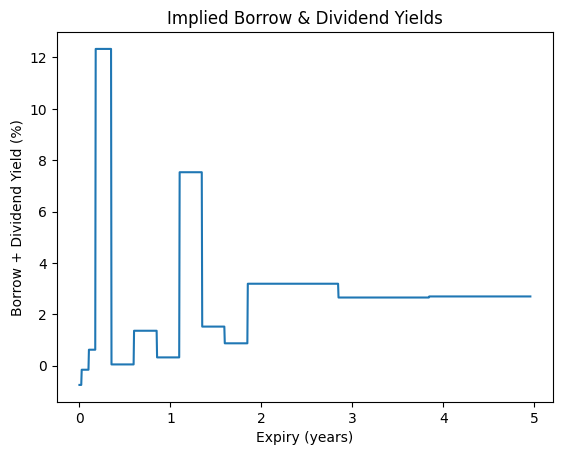

CAC40 2025-02-12 : S0 = 8042.19, 142 quotes on 13 expiries
Heston : v0=0.0197, theta=0.0438, kappa=1.3079, xi=0.4820, rho=-0.6050 | implied vol RMSE = 0.421 vol pts


In [2]:
mkt = cac40_heston()
heston, S0 = mkt.heston, mkt.S0
# Weekly grid : observation dates are discrete and the American protection uses the Brownian bridge,
# so a daily grid is only needed for the daily-monitored protection ('american_discrete').
pricer = MonteCarloPricer(n_paths=50_000, steps_per_year=52, seed=42)
daily_pricer = MonteCarloPricer(n_paths=50_000, steps_per_year=252, seed=42)

## 2. Pricing :

In [11]:
base = Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.6)

In [12]:
res = pricer.price(heston, base)

In [13]:
print(f"{base}")
print(f"Price : {res.price:.3f} +/- {1.96 * res.stderr:.3f} (95%) for a nominal of 100")
print(f"Fair coupon : {100 * base.fair_coupon(pricer, heston):.3f}% p.a.")
stats = base.statistics(pricer, heston)
pd.Series({k: v for k, v in stats.items() if k != "call probability by date"}, name="Base case").to_frame()

Athena(T=4, 16 obs, coupon 6.00% p.a., autocall 100%, protection 60% european)
Price : 97.795 +/- 0.110 (95%) for a nominal of 100
Fair coupon : 10.538% p.a.


,Base case
probability to reach maturity,0.1329
probability of a capital loss,0.05218
expected loss at maturity (% nominal),3.05192
expected life (years),1.03247
expected number of coupons,0


## 3. Sensitivities : 

In [14]:
protection_barrier = Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.0, protection_barrier=0.8)
res1 = pricer.price(heston, protection_barrier)

In [15]:
print(f"{protection_barrier}")
print(f"Price : {res1.price:.3f} +/- {1.96 * res1.stderr:.3f} (95%) for a nominal of 100")
print(f"Fair coupon : {100 * protection_barrier.fair_coupon(pricer, heston):.3f}% p.a.")
stats = protection_barrier.statistics(pricer, heston)
pd.Series({k: v for k, v in stats.items() if k != "call probability by date"}, name="Base case").to_frame()

Athena(T=4, 16 obs, coupon 6.00% p.a., autocall 100%, protection 80% european)
Price : 96.599 +/- 0.121 (95%) for a nominal of 100
Fair coupon : 13.003% p.a.


,Base case
probability to reach maturity,0.1329
probability of a capital loss,0.09568
expected loss at maturity (% nominal),4.34222
expected life (years),1.03247
expected number of coupons,0


We observe that if we increase the protection barrier from 0.6 to 0.8 the fair coupon is no more 10.322% but 12.810%. The probabiliy of capital loss is multiplied by around 2

In [16]:
autocall_barrier = Athena(4.0, S0, 0.06, frequency=0.25, autocall_barrier=1.1, protection_barrier=0.6)
res2 = pricer.price(heston, autocall_barrier)

In [17]:
print(f"{autocall_barrier}")
print(f"Price : {res2.price:.3f} +/- {1.96 * res2.stderr:.3f} (95%) for a nominal of 100")
print(f"Fair coupon : {100 * autocall_barrier.fair_coupon(pricer, heston):.3f}% p.a.")
stats = autocall_barrier.statistics(pricer, heston)
pd.Series({k: v for k, v in stats.items() if k != "call probability by date"}, name="Base case").to_frame()

Athena(T=4, 16 obs, coupon 6.00% p.a., autocall 110%, protection 60% european)
Price : 96.599 +/- 0.121 (95%) for a nominal of 100
Fair coupon : 12.687% p.a.


,Base case
probability to reach maturity,0.37564
probability of a capital loss,0.1048
expected loss at maturity (% nominal),6.03887
expected life (years),2.39018
expected number of coupons,0


## 4. Features of Athena products

We will now have a look on features that can be incorporated in the Phoenix product and their impacts on the price.

### 4.1 Exercise frequency

### 4.2 Step-down barrier

### 4.3 Airbag

### 4.4 Buffer

### 4.5 Guaranteed capital

### 4.6 Coupon range accrual

### 4.7 Duo mecanism

### Look back